# 02. Régression logistique

## Préparation

In [1]:
import sys
sys.path.append("..")
import pandas as pd
from sklearn.pipeline import Pipeline
from src.data import X_train, X_test, y_train, y_test
from src.preprocessing import prepro

#### Regression logistique

In [2]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate, GridSearchCV, StratifiedKFold

pip = Pipeline([
    ("prétraitement", prepro),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000)),
])
grid = {"model__C": [0.001, 0.01, 0.1, 1, 10, 100]}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
clf = GridSearchCV(pip,param_grid=grid, cv=cv, n_jobs=-1, scoring="f1_macro")
resultats = cross_validate(clf, X_train, y_train, cv=cv, scoring=["f1_macro", "recall", "precision", "accuracy", "roc_auc"], return_estimator=True, n_jobs=-1)


for i, e in enumerate(resultats["estimator"], 1):
    print(f"tour {i} : {e.best_params_}")

tour 1 : {'model__C': 0.1}
tour 2 : {'model__C': 0.01}
tour 3 : {'model__C': 100}
tour 4 : {'model__C': 0.1}
tour 5 : {'model__C': 10}


In [3]:
resultats[("test_f1_macro")]

array([0.49913043, 0.46712018, 0.42134063, 0.46420429, 0.48351648])

In [4]:
resultats[("test_roc_auc")].mean()

np.float64(0.4474312354312354)

In [5]:
for est in resultats["estimator"]:
    print(est.best_params_)

{'model__C': 0.1}
{'model__C': 0.01}
{'model__C': 100}
{'model__C': 0.1}
{'model__C': 10}


0.4230769230769231


<Axes: >

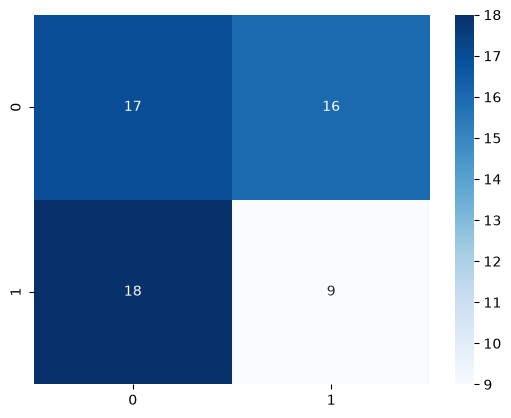

In [6]:
import seaborn as sns
from sklearn.metrics import f1_score, confusion_matrix
modele_final = Pipeline([
    ("prétraitement", prepro),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, C=0.1)),
])

modele_final.fit(X_train, y_train)

y_pred = modele_final.predict(X_test)
score=f1_score(y_test, y_pred, average="macro")
print(score)
confusion_matrix_lr = confusion_matrix(y_test, y_pred)

sns.heatmap(confusion_matrix_lr, annot=True, cmap="Blues", fmt="g", annot_kws={"size": 10})



#### Ce modèle montre les données ne nous permettent pas de choisir le meilleur C. La F1 nous montre le modèle n'arrive pas distinguer les cas familiaux des cas sporadiques. Ce résultat est cohérent avec l'analyse exploratoire parce qu'aucune variable prise isolément n'est significativement liée à la cible. Et toutes les corrélations avec la cible sont inférieures à 0.10 en valeur absolue.

In [8]:
   pd.DataFrame(resultats).drop(columns="estimator").to_csv("../results/logreg.csv", index=False)